In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Step 1: Read the CSV file
data = pd.read_csv('./Mall_Customers.csv')  

data = data.drop('CustomerID', axis=1)  # Replace 'target_column' with the name of your target column


# Step 2: Split the data into 80% training and 20% testing
train_data, test_data = train_test_split(data, test_size=0.2, random_state=42)

# Optional: Check the shapes of the resulting datasets
print(f"Training data shape: {train_data.shape}")
print(f"Testing data shape: {test_data.shape}")

# Now you can use train_data and test_data for your machine learning tasks

Training data shape: (160, 4)
Testing data shape: (40, 4)


In [2]:
train_data.head()

,Gender,Age,Annual Income (k$),Spending Score (1-100)
79,Female,49,54,42
197,Male,32,126,74
38,Female,36,37,26
24,Female,54,28,14
122,Female,40,69,58


In [3]:
def print_column_statistics(df, column_name):
    """
    Prints statistics for a specified column in a pandas DataFrame.

    Parameters:
        df (pd.DataFrame): The input DataFrame.
        column_name (str): The name of the column to analyze.
    """
    # Check if the column exists in the DataFrame
    if column_name not in df.columns:
        print(f"Error: Column '{column_name}' not found in the DataFrame.")
        return

    # Extract the column
    column_data = df[column_name]

    # Calculate statistics
    count = column_data.count()          # Number of non-missing values
    mean = column_data.mean()            # Mean (average)
    max_val = column_data.max()          # Maximum value
    min_val = column_data.min()          # Minimum value
    std_dev = column_data.std()          # Standard deviation
    quartiles = column_data.quantile([0.25, 0.5, 0.75])  # Quartiles (25%, 50%, 75%)

    # Print the statistics
    print(f"Statistics for column '{column_name}':")
    print(f"Count: {count}")
    print(f"Mean: {mean}")
    print(f"Max: {max_val}")
    print(f"Min: {min_val}")
    print(f"Standard Deviation: {std_dev}")
    print("Quartiles:")
    print(quartiles)


In [4]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 160 entries, 79 to 102
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Gender                  160 non-null    object
 1   Age                     160 non-null    int64 
 2   Annual Income (k$)      160 non-null    int64 
 3   Spending Score (1-100)  160 non-null    int64 
dtypes: int64(3), object(1)
memory usage: 6.2+ KB


In [5]:
print_column_statistics(train_data, "Age")
print_column_statistics(train_data, "Spending Score (1-100)")
print_column_statistics(train_data, "Annual Income (k$)")

Statistics for column 'Age':
Count: 160
Mean: 38.9125
Max: 70
Min: 18
Standard Deviation: 13.856582342476678
Quartiles:
0.25    29.0
0.50    36.0
0.75    49.0
Name: Age, dtype: float64
Statistics for column 'Spending Score (1-100)':
Count: 160
Mean: 51.775
Max: 99
Min: 1
Standard Deviation: 26.42062992312241
Quartiles:
0.25    35.75
0.50    50.50
0.75    74.00
Name: Spending Score (1-100), dtype: float64
Statistics for column 'Annual Income (k$)':
Count: 160
Mean: 60.60625
Max: 137
Min: 15
Standard Deviation: 27.395105121010122
Quartiles:
0.25    39.75
0.50    62.00
0.75    78.00
Name: Annual Income (k$), dtype: float64


In [38]:
all_columns = list(train_data.columns)
columns_to_normalize = all_columns
columns_to_normalize.remove("Gender")
columns_to_normalize

['Age', 'Annual Income (k$)', 'Spending Score (1-100)']

In [39]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
normalized_train_data = scaler.fit_transform(train_data[columns_to_normalize])
# type(normalized_train_data) # is array
normalized_train_data = pd.DataFrame(normalized_train_data, columns=columns_to_normalize)


normalized_train_data['Gender'] = train_data['Gender'].values
normalized_train_data.head()

,Age,Annual Income (k$),Spending Score (1-100),Gender
0,0.730279,-0.241904,-0.371138,Female
1,-0.500427,2.394554,0.843840,Male
2,-0.210849,-0.864401,-0.978626,Female
3,1.092251,-1.193959,-1.434243,Female
4,0.078729,0.307358,0.236351,Female


In [41]:
normalized_train_data.loc[normalized_train_data['Gender'] == 'Female', 'Gender'] = 1
normalized_train_data.loc[normalized_train_data['Gender'] != 1, 'Gender'] = 0

normalized_train_data.head()

,Age,Annual Income (k$),Spending Score (1-100),Gender
0,0.730279,-0.241904,-0.371138,1
1,-0.500427,2.394554,0.843840,0
2,-0.210849,-0.864401,-0.978626,1
3,1.092251,-1.193959,-1.434243,1
4,0.078729,0.307358,0.236351,1


In [42]:
import numpy as np
from sklearn.cluster import KMeans

def kmeans_clustering(k, dataframe, random_state=42):
    # Ensure dataframe is a numpy array
    data = dataframe.to_numpy() if isinstance(dataframe, pd.DataFrame) else dataframe
    
    # Initialize KMeans model with a specific random_state
    kmeans = KMeans(n_clusters=k, random_state=random_state)
    
    # Fit the model to the data
    kmeans.fit(data)
    
    # Get cluster centers
    centers = kmeans.cluster_centers_
    
    # Get cluster assignments
    labels = kmeans.labels_
    
    return centers, labels, kmeans.inertia_


In [44]:
centers, labels, inertia = kmeans_clustering(k = 3, dataframe=normalized_train_data)
print(f"centers.shape: {centers.shape}")
print(f"\nlabels.shape: {labels.shape}")
print(f"\ninertia: {inertia}")

centers.shape: (3, 4)

labels.shape: (160,)

inertia: 272.63690427261685


In [45]:
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

def find_best_k(dataframe, k_range=10, n_attempts=20):
    # Convert k_range to a range of values (2 to k_range)
    k_values = range(2, k_range + 1)
    
    wcss_values = []  # To store the best WCSS for each k
    silhouette_scores = []  # To store the best Silhouette score for each k
    
    for k in k_values:
        best_inertia = np.inf  # Track the lowest inertia (WCSS)
        best_labels = None  # Track the best labels
        best_centers = None  # Track the best centers
        best_silhouette = -1  # Track the highest Silhouette score
        
        for attempt in range(n_attempts):
            # Use a different random_state for each attempt
            random_state = attempt  # or use np.random.randint(0, 1000) for a random seed
            centers, labels, inertia = kmeans_clustering(k, dataframe, random_state)
            
            # Update best results if this attempt has a lower inertia
            if inertia < best_inertia:
                best_inertia = inertia
                best_labels = labels
                best_centers = centers
            
            # Calculate Silhouette score for this attempt
            silhouette_avg = silhouette_score(dataframe, labels)
            if silhouette_avg > best_silhouette:
                best_silhouette = silhouette_avg
        
        # Store the best results for this k
        wcss_values.append(best_inertia)
        silhouette_scores.append(best_silhouette)
    
    # Plot the Elbow method
    plt.figure(figsize=(12, 5))
    
    plt.subplot(1, 2, 1)
    plt.plot(k_values, wcss_values, 'bo-')
    plt.xlabel('Number of clusters (k)')
    plt.ylabel('Within-Cluster-Sum of Squares (WCSS)')
    plt.title('Elbow Method')
    
    # Plot the Silhouette scores
    plt.subplot(1, 2, 2)
    plt.plot(k_values, silhouette_scores, 'go-')
    plt.xlabel('Number of clusters (k)')
    plt.ylabel('Silhouette Score')
    plt.title('Silhouette Method')
    
    plt.show()
    
    
    # Find the best k based on the Silhouette score
    best_k_silhouette = k_values[np.argmax(silhouette_scores)]
    print(f"Best k based on Silhouette score: {best_k_silhouette}")
    
    return best_k_silhouette
    

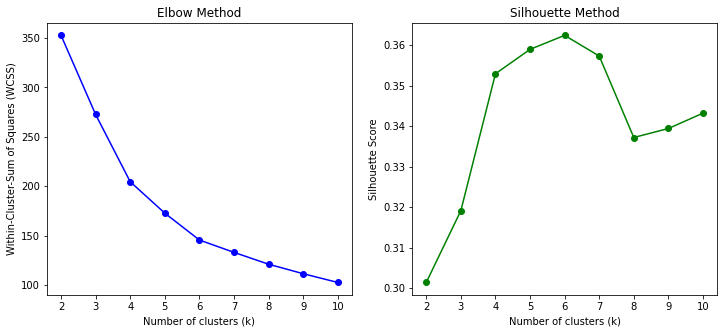

Best k based on Silhouette score: 6


6

In [47]:
find_best_k(normalized_train_data)

In [48]:
normalized_test_data = scaler.transform(test_data[columns_to_normalize])
normalized_test_data = pd.DataFrame(normalized_test_data, columns=columns_to_normalize)

normalized_test_data["Gender"] = test_data["Gender"].values
normalized_test_data.head()

,Age,Annual Income (k$),Spending Score (1-100),Gender
0,-1.079582,-0.022199,0.008543,Male
1,-1.224371,-1.486899,1.033680,Male
2,1.526618,-1.120724,-1.813923,Male
3,-0.355638,0.636915,-1.927828,Male
4,1.454224,0.380593,-1.548147,Male


In [49]:
normalized_test_data.loc[normalized_test_data['Gender'] == 'Female', 'Gender'] = 1
normalized_test_data.loc[normalized_test_data['Gender'] != 1, 'Gender'] = 0

normalized_test_data.head()

,Age,Annual Income (k$),Spending Score (1-100),Gender
0,-1.079582,-0.022199,0.008543,0
1,-1.224371,-1.486899,1.033680,0
2,1.526618,-1.120724,-1.813923,0
3,-0.355638,0.636915,-1.927828,0
4,1.454224,0.380593,-1.548147,0


In [51]:
kmeans = KMeans(n_clusters=6, random_state=42)
kmeans.fit(normalized_train_data)

# Step 2: Predict cluster labels for the test data
test_labels = kmeans.predict(normalized_test_data)

# Step 3: Calculate evaluation metrics
# Inertia (WCSS)
inertia = kmeans.inertia_

# Silhouette Score
silhouette_avg = silhouette_score(normalized_test_data, test_labels)


# Step 4: Print the results
print(f"Inertia (WCSS): {inertia}")
print(f"Silhouette Score: {silhouette_avg}")

Inertia (WCSS): 145.471120305591
Silhouette Score: 0.30693218488637547


In [62]:
# Step 1: Add the predicted cluster labels to the normalized test data
normalized_test_data['Cluster'] = test_labels

# Step 2: Save the DataFrame to a CSV file
normalized_test_data.to_csv('predicts.csv', index=False)

print("Data saved to predicts.csv")

normalized_test_data.drop("Cluster",axis=1,inplace=True)


Data saved to predicts.csv


In [71]:
from sklearn.decomposition import PCA


pca = PCA(n_components=2)
pca_data = pca.fit_transform(normalized_train_data)

# Step 3: Transform both training and test data using the fitted PCA model
train_pca = pca.transform(normalized_train_data)
test_pca = pca.transform(normalized_test_data)

# Step 4: Create DataFrames for the PCA-transformed data
train_pca_df = pd.DataFrame(data=train_pca, columns=['PCA1', 'PCA2'])
test_pca_df = pd.DataFrame(data=test_pca, columns=['PCA1', 'PCA2'])

# Step 5: (Optional) Add the original columns for reference
train_pca_df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)', 'Gender']] = normalized_train_data
test_pca_df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)', 'Gender']] = normalized_test_data

print("PCA-transformed Training Data:")
train_pca_df.head()


PCA-transformed Training Data:


,PCA1,PCA2,Age,Annual Income (k$),Spending Score (1-100),Gender
0,0.802477,-0.093216,0.730279,-0.241904,-0.371138,1
1,-1.369898,2.216659,-0.500427,2.394554,0.843840,0
2,0.693793,-0.839667,-0.210849,-0.864401,-0.978626,1
3,1.972032,-0.882292,1.092251,-1.193959,-1.434243,1
4,-0.173404,0.278036,0.078729,0.307358,0.236351,1


In [72]:
print("\nPCA-transformed Test Data:")
test_pca_df.head()


PCA-transformed Test Data:


,PCA1,PCA2,Age,Annual Income (k$),Spending Score (1-100),Gender
0,-0.738924,-0.199944,-1.079582,-0.022199,0.008543,0
1,-1.286930,-1.730470,-1.224371,-1.486899,1.033680,0
2,2.536738,-0.652327,1.526618,-1.120724,-1.813923,0
3,0.995018,0.715716,-0.355638,0.636915,-1.927828,0
4,2.024098,0.783913,1.454224,0.380593,-1.548147,0


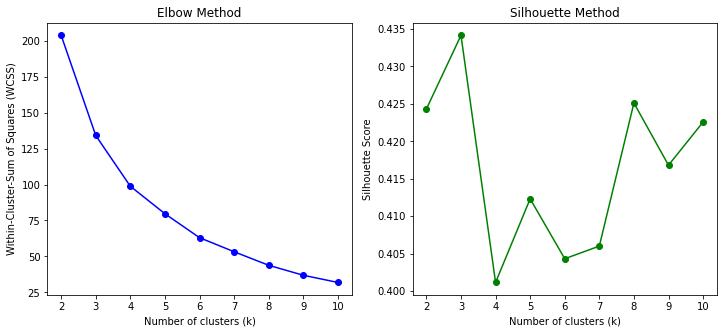

Best k based on Silhouette score: 3


3

In [76]:
find_best_k(train_pca_df[["PCA1","PCA2"]])

In [77]:
# Step 1: Train a KMeans model with k=3 on the PCA-transformed training data
kmeans_pca = KMeans(n_clusters=3, random_state=42)
kmeans_pca.fit(train_pca_df[['PCA1', 'PCA2']])  # Use only the PCA components for training

# Step 2: Predict cluster labels for the PCA-transformed test data
pca_test_labels = kmeans_pca.predict(test_pca_df[['PCA1', 'PCA2']])

# Step 3: Load the existing `predicts.csv` file
predicts_df = pd.read_csv('predicts.csv')

# Step 4: Add the PCA-based cluster labels to the DataFrame
predicts_df['PCA_Cluster'] = pca_test_labels

# Step 5: Save the updated DataFrame back to `predicts.csv`
predicts_df.to_csv('predicts.csv', index=False)

print("Updated predicts.csv with PCA-based cluster labels:")
predicts_df.head()

Updated predicts.csv with PCA-based cluster labels:


,Age,Annual Income (k$),Spending Score (1-100),Gender,Cluster,PCA_Cluster
0,-1.079582,-0.022199,0.008543,0,3,0
1,-1.224371,-1.486899,1.033680,0,1,0
2,1.526618,-1.120724,-1.813923,0,0,1
3,-0.355638,0.636915,-1.927828,0,2,1
4,1.454224,0.380593,-1.548147,0,2,1


C:\python\lib\site-packages\sklearn\base.py:450: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(
C:\python\lib\site-packages\sklearn\base.py:450: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


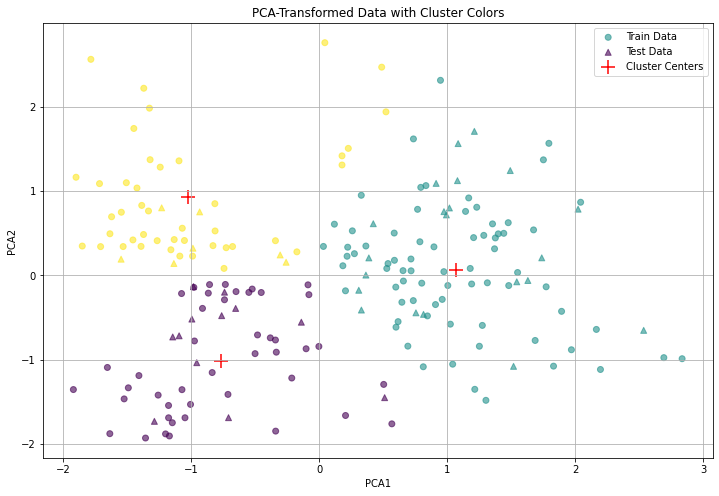

In [91]:
import matplotlib.pyplot as plt

# Assuming `train_pca` and `test_pca` are numpy arrays with shape (n_samples, 6)
# Columns 0 and 1: PCA1 and PCA2 (PCA-transformed attributes)
# Columns 2-5: Original features (e.g., Age, Annual Income, Spending Score, Gender)

# Step 1: Get the PCA-transformed columns (first two columns)
train_pca_transformed = train_pca[:, :2]  # PCA1 and PCA2 for training data
test_pca_transformed = test_pca[:, :2]    # PCA1 and PCA2 for test data

# Step 2: Get the cluster centers in PCA space
cluster_centers_pca = kmeans_pca.cluster_centers_

# Step 3: Predict cluster labels for training and test data
train_cluster_labels = kmeans_pca.predict(train_pca_transformed)
test_cluster_labels = kmeans_pca.predict(test_pca_transformed)

# Step 4: Create the scatter plot
plt.figure(figsize=(12, 8))

# Plot training data (circles) with cluster colors
plt.scatter(train_pca_transformed[:, 0], train_pca_transformed[:, 1], c=train_cluster_labels, cmap='viridis', marker='o', label='Train Data', alpha=0.6)

# Plot test data (triangles) with cluster colors
plt.scatter(test_pca_transformed[:, 0], test_pca_transformed[:, 1], c=test_cluster_labels, cmap='viridis', marker='^', label='Test Data', alpha=0.6)

# Plot cluster centers (plus signs)
plt.scatter(cluster_centers_pca[:, 0], cluster_centers_pca[:, 1], c='red', marker='+', s=200, label='Cluster Centers')

# Add labels, title, and legend
plt.xlabel('PCA1')
plt.ylabel('PCA2')
plt.title('PCA-Transformed Data with Cluster Colors')
plt.legend()
plt.grid(True)

# Show the plot
plt.show()

In [92]:
print("Explained variance ratio:", pca.explained_variance_ratio_)

silhouette_avg = silhouette_score(train_pca, kmeans_pca.labels_)
print("\nSilhouette Score:", silhouette_avg)

Explained variance ratio: [0.40735709 0.30589283]

Silhouette Score: 0.42943516551800326
